# Practical: Air-Quality Data Cleaning Using R

**Topic:** Loops, Functions, Error Handling, and Advanced Missing Data Handling
**Subtopic:** Management of NA, NULL, and NaN Values
**Dataset:** Beijing Multi-Site Air Quality Dataset (UCI ML Repository) — station file `PRSA_Data_Aotizhongxin_20130301-20170228.csv`

This notebook runs on Colab's **R runtime**. Before running, go to `Runtime > Change runtime type` and select **R**.

The dataset is downloaded automatically in the setup cell below, so no manual upload is needed.

## Setup: Packages and Dataset Download

In [16]:
# Install/load required packages
required_packages <- c("ggplot2", "dplyr")
for (pkg in required_packages) {
  if (!require(pkg, character.only = TRUE)) {
    install.packages(pkg)
    library(pkg, character.only = TRUE)
  }
}

zip_file <- "PRSA2017_Data_20130301-20170228.zip"
data_dir <- "PRSA_Data_20130301-20170228"

# Check if folder exists; if not, download or unzip
if (!dir.exists(data_dir)) {
  if (!file.exists(zip_file)) {
    cat("Dataset zip not found. Downloading from UCI Repository...\n")
    download.url <- "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
    download.file(download.url, destfile = "beijing_dataset.zip", mode = "wb")
    unzip("beijing_dataset.zip", exdir = ".")
    if (file.exists("beijing_dataset.zip")) file.remove("beijing_dataset.zip")
  }

  if (file.exists(zip_file)) {
    cat("Unzipping dataset...\n")
    unzip(zip_file, exdir = ".")
  }
}

if (!dir.exists(data_dir)) {
  stop("Could not find or extract the dataset directory.")
}

# Find the CSV files
station_files <- list.files(data_dir, pattern = "\\.csv$", full.names = TRUE)

if (length(station_files) == 0) {
  stop(sprintf("No CSV file found inside '%s'.", data_dir))
}

# We filter specifically for the Aotizhongxin CSV file
aoti_file <- grep("Aotizhongxin", station_files, value = TRUE)
if (length(aoti_file) > 0) {
  station_file <- aoti_file[1]
} else {
  station_file <- station_files[1]
}

cat("Using dataset file:", station_file, "\n")
station_file

Using dataset file: PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv 


[1] "PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv"

## Task 1: Import and Inspect the Dataset

Import the station CSV, inspect it, and check for missing values. `tryCatch()` gives a meaningful message if the file is missing, unreadable, or malformed.

In [17]:
air_data <- tryCatch({
  read.csv(station_file, stringsAsFactors = FALSE)
}, error = function(e) {
  message("Error while reading the dataset: ", e$message)
  NULL
}, warning = function(w) {
  message("Warning while reading the dataset: ", w$message)
  suppressWarnings(read.csv(station_file, stringsAsFactors = FALSE))
})

if (is.null(air_data)) {
  stop("Dataset could not be loaded. Check 'station_file' path and try again.")
}

cat("First six records:\n")
print(head(air_data))

cat("\nStructure of dataset:\n")
str(air_data)

cat("\nNumber of rows and columns:\n")
print(dim(air_data))

cat("\nDoes the dataset contain missing values? ", any(is.na(air_data)), "\n")
cat("Total number of missing values: ", sum(is.na(air_data)), "\n")

First six records:
  No year month day hour PM2.5 PM10 SO2 NO2  CO O3 TEMP   PRES  DEWP RAIN  wd
1  1 2013     3   1    0     4    4   4   7 300 77 -0.7 1023.0 -18.8    0 NNW
2  2 2013     3   1    1     8    8   4   7 300 77 -1.1 1023.2 -18.2    0   N
3  3 2013     3   1    2     7    7   5  10 300 73 -1.1 1023.5 -18.2    0 NNW
4  4 2013     3   1    3     6    6  11  11 300 72 -1.4 1024.5 -19.4    0  NW
5  5 2013     3   1    4     3    3  12  12 300 72 -2.0 1025.2 -19.5    0   N
6  6 2013     3   1    5     5    5  18  18 400 66 -2.2 1025.6 -19.6    0   N
  WSPM      station
1  4.4 Aotizhongxin
2  4.7 Aotizhongxin
3  5.6 Aotizhongxin
4  3.1 Aotizhongxin
5  2.0 Aotizhongxin
6  3.7 Aotizhongxin

Structure of dataset:
'data.frame':	35064 obs. of  18 variables:
 $ No     : int  1 2 3 4 5 6 7 8 9 10 ...
 $ year   : int  2013 2013 2013 2013 2013 2013 2013 2013 2013 2013 ...
 $ month  : int  3 3 3 3 3 3 3 3 3 3 ...
 $ day    : int  1 1 1 1 1 1 1 1 1 1 ...
 $ hour   : int  0 1 2 3 4 5 6 7 8

## Task 2: Understand NA, NULL, and NaN

In [18]:
# NA - an unavailable/missing observation
temperature <- c(28, 30, NA, 32)
cat("temperature vector:", temperature, "\n")
cat("is.na(temperature):", is.na(temperature), "\n\n")

# NULL - an absent/empty R object
missing_object <- NULL
cat("missing_object is NULL:", is.null(missing_object), "\n")
cat("length(missing_object):", length(missing_object), "\n\n")

# NaN - an undefined numerical result
undefined_value <- 0 / 0
cat("undefined_value (0/0):", undefined_value, "\n")
cat("is.nan(undefined_value):", is.nan(undefined_value), "\n")
cat("is.na(undefined_value):", is.na(undefined_value), "  # NaN also registers as NA\n")

temperature vector: 28 30 NA 32 
is.na(temperature): FALSE FALSE TRUE FALSE 

missing_object is NULL: TRUE 
length(missing_object): 0 

undefined_value (0/0): NaN 
is.nan(undefined_value): TRUE 
is.na(undefined_value): TRUE   # NaN also registers as NA


## Task 3: Missing-Value Summary Function

`missing_summary()` takes a data frame and reports total records, missing values, and missing percentage per variable, warning when any variable exceeds 20% missing.

In [19]:
missing_summary <- function(df) {
  vars <- names(df)
  total_records <- nrow(df)

  rows <- lapply(vars, function(v) {
    missing_count <- sum(is.na(df[[v]]))
    missing_pct <- round((missing_count / total_records) * 100, 2)

    if (missing_pct > 20) {
      warning(sprintf("Variable '%s' has more than 20%% missing values (%.2f%%)", v, missing_pct))
    }

    data.frame(Variable = v, Total_Records = total_records,
               Missing_Values = missing_count, Missing_Percentage = missing_pct,
               stringsAsFactors = FALSE)
  })

  do.call(rbind, rows)
}

selected_vars <- c("PM2.5", "PM10", "SO2", "NO2", "TEMP", "WSPM", "wd")
summary_table <- missing_summary(air_data[, selected_vars])
print(summary_table)

  Variable Total_Records Missing_Values Missing_Percentage
1    PM2.5         35064            925               2.64
2     PM10         35064            718               2.05
3      SO2         35064            935               2.67
4      NO2         35064           1023               2.92
5     TEMP         35064             20               0.06
6     WSPM         35064             14               0.04
7       wd         35064             81               0.23


## Task 4: Identify Invalid Numerical Results

Create `pollution_ratio = PM2.5 / PM10`, check for NA/NaN/Inf, and clean it.

In [20]:
air_data$pollution_ratio <- air_data$PM2.5 / air_data$PM10

cat("NA count in pollution_ratio:", sum(is.na(air_data$pollution_ratio)), "\n")
cat("NaN count in pollution_ratio:", sum(is.nan(air_data$pollution_ratio)), "\n")
cat("Positive Inf count:", sum(air_data$pollution_ratio == Inf, na.rm = TRUE), "\n")
cat("Negative Inf count:", sum(air_data$pollution_ratio == -Inf, na.rm = TRUE), "\n")

air_data$pollution_ratio[is.nan(air_data$pollution_ratio) | is.infinite(air_data$pollution_ratio)] <- NA

cat("\nRemaining NaN/Inf after cleanup:",
    sum(is.nan(air_data$pollution_ratio) | is.infinite(air_data$pollution_ratio), na.rm = TRUE), "\n")

NA count in pollution_ratio: 934 
NaN count in pollution_ratio: 0 
Positive Inf count: 0 
Negative Inf count: 0 

Remaining NaN/Inf after cleanup: 0 


## Task 5: Handle Missing Numerical Values Using a Loop

A single `for` loop processes every numerical variable — no repeated per-variable code.

In [21]:
numeric_variables <- c("PM2.5", "PM10", "SO2", "NO2", "TEMP", "WSPM")

missing_before <- c()
missing_after  <- c()
medians_used   <- c()

for (var in numeric_variables) {
  if (!(var %in% names(air_data))) {
    cat("Column", var, "does not exist. Skipping.\n")
    next
  }

  before_count <- sum(is.na(air_data[[var]]))
  med_val <- median(air_data[[var]], na.rm = TRUE)
  air_data[[var]][is.na(air_data[[var]])] <- med_val
  after_count <- sum(is.na(air_data[[var]]))

  missing_before[var] <- before_count
  missing_after[var]  <- after_count
  medians_used[var]   <- med_val

  cat(sprintf("Variable: %-6s | Missing before: %4d | Median used: %7.2f | Missing after: %d\n",
              var, before_count, med_val, after_count))
}

Variable: PM2.5  | Missing before:  925 | Median used:   58.00 | Missing after: 0
Variable: PM10   | Missing before:  718 | Median used:   87.00 | Missing after: 0
Variable: SO2    | Missing before:  935 | Median used:    9.00 | Missing after: 0
Variable: NO2    | Missing before: 1023 | Median used:   53.00 | Missing after: 0
Variable: TEMP   | Missing before:   20 | Median used:   14.50 | Missing after: 0
Variable: WSPM   | Missing before:   14 | Median used:    1.40 | Missing after: 0


## Task 6: Handle Missing Categorical Values

`calculate_mode()` finds the most frequent value of `wd` (wind direction) and uses it to fill missing entries.

In [22]:
calculate_mode <- function(x) {
  x <- x[!is.na(x) & x != ""]
  freq_table <- table(x)
  names(freq_table)[which.max(freq_table)]
}

wd_missing_before <- sum(is.na(air_data$wd) | air_data$wd == "")
wd_mode <- calculate_mode(air_data$wd)
air_data$wd[is.na(air_data$wd) | air_data$wd == ""] <- wd_mode
wd_missing_after <- sum(is.na(air_data$wd) | air_data$wd == "")

cat("Mode of wd:", wd_mode, "\n")
cat("Missing before:", wd_missing_before, "| Missing after:", wd_missing_after, "\n")

Mode of wd: NE 
Missing before: 81 | Missing after: 0 


## Task 7: Implement Error Handling

`clean_variable()` validates the variable exists, is numeric, and isn't entirely missing before imputing with the median, using `tryCatch()` to report problems without stopping the program.

In [23]:
clean_variable <- function(df, var_name) {
  tryCatch({
    if (!(var_name %in% names(df))) {
      stop(sprintf("Variable '%s' does not exist in the dataset.", var_name))
    }

    variable <- df[[var_name]]

    if (!is.numeric(variable)) {
      stop(sprintf("Variable '%s' is categorical, not numerical.", var_name))
    }

    if (all(is.na(variable))) {
      stop(sprintf("Variable '%s' contains only missing values.", var_name))
    }

    med_val <- median(variable, na.rm = TRUE)

    if (is.na(med_val)) {
      stop(sprintf("Median could not be calculated for '%s'.", var_name))
    }

    variable[is.na(variable)] <- med_val
    variable

  }, error = function(e) {
    message("clean_variable() error: ", e$message)
    NULL
  })
}

# Demonstrations of each error condition
cat("-- Non-existent column --\n")
test1 <- clean_variable(air_data, "NonExistentColumn")

cat("\n-- Categorical column passed as numeric --\n")
test2 <- clean_variable(air_data, "wd")

cat("\n-- Valid numerical column (CO) --\n")
test3 <- clean_variable(air_data, "CO")
if (!is.null(test3)) {
  air_data$CO <- test3
  cat("CO cleaned successfully. Remaining NAs:", sum(is.na(air_data$CO)), "\n")
}

-- Non-existent column --


clean_variable() error: Variable 'NonExistentColumn' does not exist in the dataset.




-- Categorical column passed as numeric --


clean_variable() error: Variable 'wd' is categorical, not numerical.




-- Valid numerical column (CO) --
CO cleaned successfully. Remaining NAs: 0 


## Task 8: Compare Missing Values Before and After Cleaning

In [24]:
compare_vars <- c(numeric_variables, "wd")

missing_before_all <- c(missing_before, wd = wd_missing_before)
missing_after_all  <- c(missing_after,  wd = wd_missing_after)

comparison_table <- data.frame(
  Variable        = compare_vars,
  Missing_Before  = as.numeric(missing_before_all[compare_vars]),
  Missing_After   = as.numeric(missing_after_all[compare_vars]),
  stringsAsFactors = FALSE
)
comparison_table$Values_Replaced <- comparison_table$Missing_Before - comparison_table$Missing_After

print(comparison_table)

all_handled <- all(comparison_table$Missing_After == 0)
cat("\nAll selected missing values successfully handled:", all_handled, "\n")

  Variable Missing_Before Missing_After Values_Replaced
1    PM2.5            925             0             925
2     PM10            718             0             718
3      SO2            935             0             935
4      NO2           1023             0            1023
5     TEMP             20             0              20
6     WSPM             14             0              14
7       wd             81             0              81

All selected missing values successfully handled: TRUE 


## Task 9: Visualization — Missing Values Before vs After

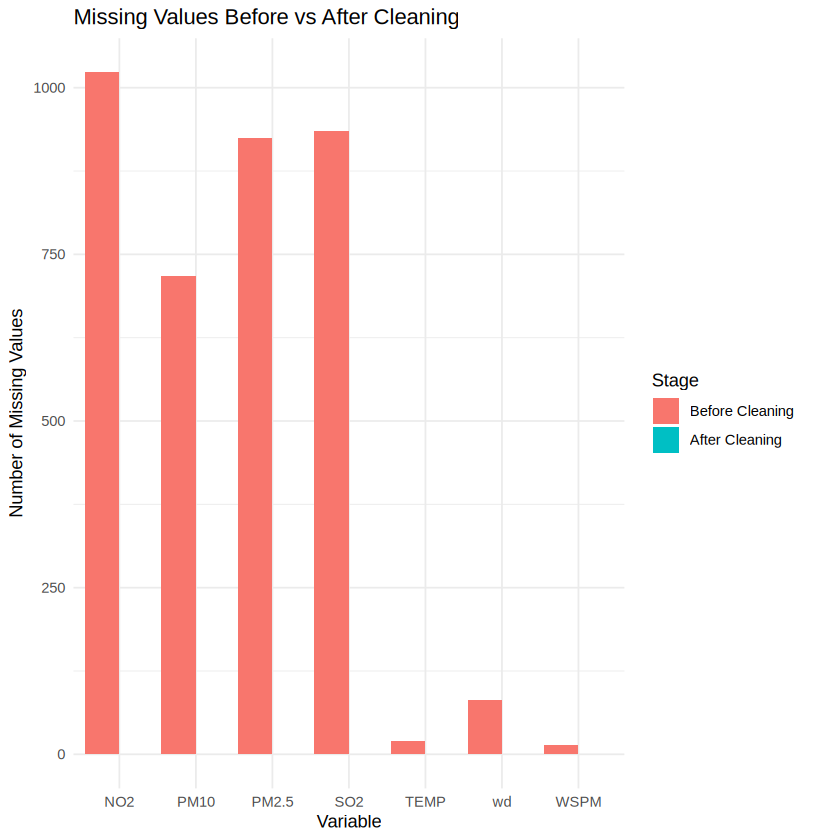

In [25]:
plot_data <- rbind(
  data.frame(Variable = comparison_table$Variable, Count = comparison_table$Missing_Before, Stage = "Before Cleaning"),
  data.frame(Variable = comparison_table$Variable, Count = comparison_table$Missing_After,  Stage = "After Cleaning")
)
plot_data$Stage <- factor(plot_data$Stage, levels = c("Before Cleaning", "After Cleaning"))

ggplot(plot_data, aes(x = Variable, y = Count, fill = Stage)) +
  geom_bar(stat = "identity", position = "dodge") +
  labs(title = "Missing Values Before vs After Cleaning",
       x = "Variable", y = "Number of Missing Values", fill = "Stage") +
  theme_minimal()

## Task 10: Export the Cleaned Dataset

In [26]:
write.csv(air_data, "cleaned_air_quality_data.csv", row.names = FALSE)
cat("Cleaned dataset exported as cleaned_air_quality_data.csv\n")
cat("(In Colab, find it in the Files pane on the left, or download it from there.)\n")

Cleaned dataset exported as cleaned_air_quality_data.csv
(In Colab, find it in the Files pane on the left, or download it from there.)
